# Cross-sensor detections: from a raw ratio to an occupancy correction

A **cell-day** is one 0.01° grid cell on one date. **VIIRS multiplicity** is the number of VIIRS
detections in that cell-day. `P(M|V, bin)` is the share of VIIRS cell-days in a bin that also hold
a MODIS detection: a co-location indicator, not a detection probability.

In [1]:
from pathlib import Path

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)


In [2]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW = ROOT / "data" / "raw"
ARTIFACTS = ROOT / "web" / "public" / "artifacts"

GRID_DEG = 0.01
THREADS = 2  # this machine overheats at four

BINS = ["1", "2-3", "4-7", "8+"]
BIN_SQL = """case when n_viirs = 1 then 1
                  when n_viirs <= 3 then 2
                  when n_viirs <= 7 then 3
                  else 4 end"""

TOL_P = 1e-8        # model/CA.json stores probabilities to 8 dp
TOL_CORRECTION = 5e-3   # ... and corrections to 2 dp
TOL_CI = 1e-4       # ... and intervals to 4 dp
TOL_COUNT = 0.01    # calendar/CA.json stores counts to 2 dp
TOL_RATIO = 5e-4    # ... and ratios to 3 dp
TOL_LOSS = 5e-4     # ... and log-loss to 4 dp

con = duckdb.connect(config={"threads": THREADS})


def sql_paths(paths):
    return ", ".join(f"'{path.as_posix()}'" for path in paths)


def country_files(sensor, years, country):
    """Every expected CSV must exist; a missing year is an error, not an empty frame."""
    paths = [RAW / f"{sensor}_{year}_{country}.csv" for year in years]
    missing = [path.name for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(f"missing raw CSVs: {missing}")
    return paths


## Raw ratio and matched ratio, Argentina 2019

Whole files with no quality filter, which is the published raw comparison. Ratios are
VIIRS ÷ MODIS. A cell-day is counted once per sensor however many pixels it holds.

In [3]:
ar_files = (
    country_files("modis", [2019], "Argentina")
    + country_files("viirs-snpp", [2019], "Argentina")
)
_ = con.sql(f"""
    create view ar as
    select case when filename ilike '%viirs%' then 'VIIRS' else 'MODIS' end as sensor,
           round(latitude / {GRID_DEG})::bigint as clat,
           round(longitude / {GRID_DEG})::bigint as clon,
           acq_date
    from read_csv([{sql_paths(ar_files)}], union_by_name=true, filename=true)
""")

ar = con.sql("""
    select sensor,
           count(*) as detections,
           count(distinct (clat, clon, acq_date)) as cell_days
    from ar
    group by 1 order by 1
""").df().set_index("sensor")

ratio_table = pd.DataFrame({
    "MODIS": [ar.loc["MODIS", "detections"], ar.loc["MODIS", "cell_days"]],
    "VIIRS": [ar.loc["VIIRS", "detections"], ar.loc["VIIRS", "cell_days"]],
    "VIIRS / MODIS": [
        ar.loc["VIIRS", "detections"] / ar.loc["MODIS", "detections"],
        ar.loc["VIIRS", "cell_days"] / ar.loc["MODIS", "cell_days"],
    ],
}, index=["detections", "cell-days"])

assert round(ratio_table.loc["detections", "VIIRS / MODIS"], 2) == 3.21
assert round(ratio_table.loc["cell-days", "VIIRS / MODIS"], 2) == 2.08
ratio_table.round(4)

,MODIS,VIIRS,VIIRS / MODIS
detections,50370,161688,3.2100
cell-days,46519,96675,2.0782


## The multiplicity curve, Canada 2012–2022

Analysis frame of the published artifacts: `type = 0` for vegetation fires, `frp > 0`, VIIRS is
Suomi NPP and MODIS is Terra + Aqua merged. One row per 0.01° cell-day.

In [4]:
ca_files = (
    country_files("modis", range(2012, 2026), "Canada")
    + country_files("viirs-snpp", range(2012, 2026), "Canada")
)
_ = con.sql(f"""
    create view raw as
    select case when filename ilike '%viirs%' then 'VIIRS' else 'MODIS' end as sensor,
           latitude, longitude, acq_date, satellite
    from read_csv([{sql_paths(ca_files)}], union_by_name=true, filename=true)
    where type = 0 and frp > 0
""")

In [5]:
_ = con.sql(f"""
    create table cd as
    select sensor, satellite,
           round(latitude / {GRID_DEG})::bigint as clat,
           round(longitude / {GRID_DEG})::bigint as clon,
           acq_date, count(*) as n
    from raw
    group by 1, 2, 3, 4, 5
""")

In [6]:
_ = con.sql("""
    create table ev as
    select clat, clon, acq_date,
           cast(extract(year from acq_date) as int) as yr,
           coalesce(sum(n) filter (where sensor = 'MODIS'), 0) as n_modis,
           coalesce(sum(n) filter (where sensor = 'VIIRS'), 0) as n_viirs
    from cd
    group by 1, 2, 3
""")

In [7]:
def wilson(hits, n, z=1.96):
    p = hits / n
    denom = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denom
    return centre - half, centre + half


cal = con.sql(f"""
    select {BIN_SQL} as bin,
           count(*) as events,
           count(*) filter (where n_modis > 0) as hits
    from ev
    where n_viirs > 0 and yr between 2012 and 2022
    group by 1 order by 1
""").df()
cal["label"] = BINS
cal["p"] = cal.hits / cal.events
cal["ci_low"], cal["ci_high"] = zip(*[wilson(h, n) for h, n in zip(cal.hits, cal.events)])
cal[["label", "events", "hits", "p", "ci_low", "ci_high"]].round(4)

,label,events,hits,p,ci_low,ci_high
0,1,506113,68973,0.1363,0.1353,0.1372
1,2-3,374945,95940,0.2559,0.2545,0.2573
2,4-7,216320,94576,0.4372,0.4351,0.4393
3,8+,53041,34322,0.6471,0.6430,0.6511


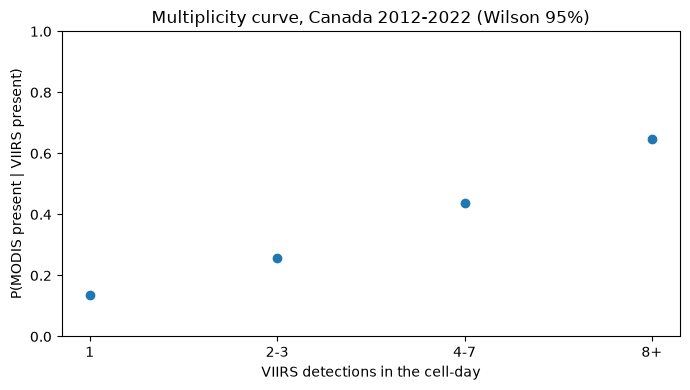

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    cal.label, cal.p,
    yerr=[cal.p - cal.ci_low, cal.ci_high - cal.p],
    fmt="o", capsize=3,
)
ax.set(
    xlabel="VIIRS detections in the cell-day",
    ylabel="P(MODIS present | VIIRS present)",
    ylim=(0, 1),
    title="Multiplicity curve, Canada 2012-2022 (Wilson 95%)",
)
plt.tight_layout()
fig.savefig(FIGURES / 'multiplicity-curve-ca-2012-2022.png', dpi=150)

## Calibrate 2012–2022, apply unchanged after

The four probabilities are the model. `correction = 1 / p` is how many VIIRS-only cell-days one
bin stands for; it replaces a single global ratio.

In [9]:
p_by_bin = {int(row.bin): float(row.hits / row.events) for row in cal.itertuples()}
_ = con.sql("""
    create table pbin as
    select * from (values
        (1, ?), (2, ?), (3, ?), (4, ?)
    ) as t(bin, p)
""", params=[p_by_bin[i] for i in range(1, 5)])

In [10]:
_ = con.sql(f"""
    create table harm as
    select ev.*,
           case when n_modis > 0 then 1.0
                when n_viirs > 0 then pbin.p
                else 0.0 end as harmonized
    from ev
    left join pbin on pbin.bin = {BIN_SQL}
""")

In [11]:
model_table = pd.DataFrame({"bin": BINS, "p": [p_by_bin[i] for i in range(1, 5)]})
model_table["correction"] = 1 / model_table.p
model_table.assign(
    p=model_table.p.map(lambda value: f"{value:.8f}"),
    correction=model_table.correction.map(lambda value: f"{value:.2f}"),
)

,bin,p,correction
0,1,0.13627984,7.34
1,2-3,0.25587753,3.91
2,4-7,0.43720414,2.29
3,8+,0.64708433,1.55


## The 2023 total

Annual totals after applying the curve. 2023 is out of sample: its probabilities were fixed on
2012–2022.

In [12]:
annual = con.sql("""
    select yr,
           count(*) filter (where n_modis > 0) as modis,
           sum(harmonized) as harmonized
    from harm
    group by 1 order by 1
""").df()
total_2023 = float(annual.loc[annual.yr == 2023, "harmonized"].iloc[0])
annual.assign(harmonized=annual.harmonized.round(2))

,yr,modis,harmonized
0,2012,33359,45582.86
1,2013,54989,76928.00
2,2014,63057,97951.21
3,2015,60224,81734.86
4,2016,22795,31041.80
5,2017,73477,100044.80
6,2018,49511,68690.29
7,2019,32147,43415.25
8,2020,10893,14464.28
9,2021,74770,100473.21


## What the correction does to a year

Canada, 2023, daily. Four series on one axis: what each sensor counted, what a naive sum
gives, and what the harmonized series gives. The naive sum treats two instruments as one
unit and counts every cell-day both sensors saw twice.


In [13]:
daily_2023 = (
    con.sql("""
        select cast(dayofyear(acq_date) as int) as doy,
               count(*) filter (where n_modis > 0) as modis,
               count(*) filter (where n_viirs > 0) as viirs,
               sum(harmonized) as harmonized
        from harm
        where yr = 2023
        group by 1 order by 1
    """)
    .df()
    .set_index("doy")
    .reindex(range(1, 366), fill_value=0)
)
daily_2023["naive"] = daily_2023.modis + daily_2023.viirs

totals = daily_2023[["modis", "viirs", "naive", "harmonized"]].sum().round(0)
assert int(totals.modis) == 253_699
assert int(totals.viirs) == 584_177
assert int(totals.naive) == 837_876
assert abs(totals.harmonized - 355_541.97) < 1.0
totals.to_frame("cell-days in 2023")


,cell-days in 2023
modis,253699.0
viirs,584177.0
naive,837876.0
harmonized,355542.0


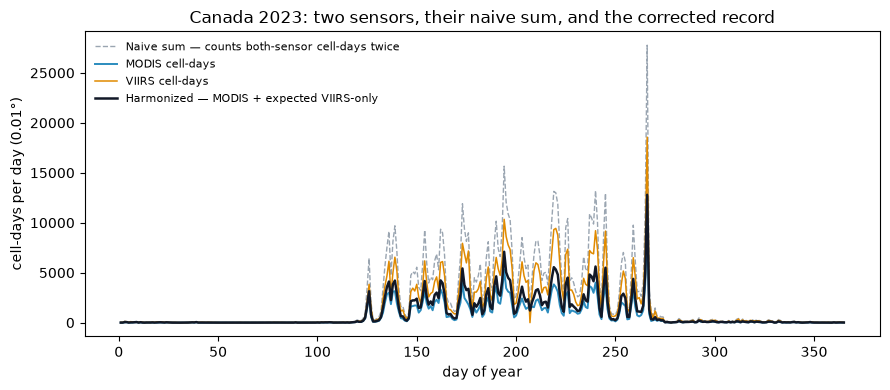

In [14]:
days = daily_2023.index.to_numpy()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, daily_2023.naive, color="#9aa5b1", lw=1, ls="--",
        label="Naive sum — counts both-sensor cell-days twice")
ax.plot(days, daily_2023.modis, color="#2b8cbe", lw=1.4, label="MODIS cell-days")
ax.plot(days, daily_2023.viirs, color="#e08a00", lw=1.1, label="VIIRS cell-days")
ax.plot(days, daily_2023.harmonized, color="#111827", lw=1.8,
        label="Harmonized — MODIS + expected VIIRS-only")
ax.set(
    xlabel="day of year",
    ylabel="cell-days per day (0.01°)",
    title="Canada 2023: two sensors, naive sum, and the corrected record",
)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES / "correction-2023-daily.png", dpi=150)


## Validation on 2023: log-loss

Train on Argentina 2019, test on Canada 2023. Log-loss is `-mean(y log p + (1-y) log(1-p))`,
lower is better, with `y = 1` when MODIS also saw the cell-day. FRP is the VIIRS cell-day maximum,
multiplicity its VIIRS pixel count; both enter as logs and the fit is logistic.

In [15]:
def colocation(label, country, year):
    paths = (
        country_files("modis", [year], country)
        + country_files("viirs-snpp", [year], country)
    )
    return con.sql(f"""
        with cd as (
            select case when filename ilike '%viirs%' then 'VIIRS' else 'MODIS' end as sensor,
                   round(latitude / {GRID_DEG})::bigint as clat,
                   round(longitude / {GRID_DEG})::bigint as clon,
                   acq_date, count(*) as n, max(frp) as frp_max
            from read_csv([{sql_paths(paths)}], union_by_name=true, filename=true)
            where type = 0 and frp > 0
            group by 1, 2, 3, 4
        )
        select '{label}' as label, clat, clon, acq_date,
               coalesce(sum(n) filter (where sensor = 'MODIS'), 0) as n_modis,
               coalesce(sum(n) filter (where sensor = 'VIIRS'), 0) as n_viirs,
               coalesce(max(frp_max) filter (where sensor = 'VIIRS'), 0) as frp_viirs
        from cd
        group by 1, 2, 3, 4
    """).df()

In [16]:
evidence = pd.concat(
    [colocation("AR-2019", "Argentina", 2019), colocation("CA-2023", "Canada", 2023)],
    ignore_index=True,
)
evidence = evidence[evidence.n_viirs > 0].assign(
    hit=lambda frame: (frame.n_modis > 0).astype(int),
    log_frp=lambda frame: np.log1p(frame.frp_viirs),
    log_mult=lambda frame: np.log(frame.n_viirs),
)
evidence.groupby("label").hit.agg(events="size", hit_rate="mean").round(4)

,events,hit_rate
label,,
AR-2019,93093,0.1658
CA-2023,584177,0.2878


In [17]:
def design(frame, columns):
    return np.column_stack([np.ones(len(frame))] + [frame[c].to_numpy(float) for c in columns])


def fit_logistic(X, y, l2=1e-3):
    def loss(w):
        return np.mean(np.logaddexp(0, X @ w) - y * (X @ w)) + l2 * np.dot(w[1:], w[1:])

    result = minimize(loss, np.zeros(X.shape[1]), method="L-BFGS-B")
    if not result.success:
        raise RuntimeError(result.message)
    return result.x


def log_loss(y, p):
    return -np.mean(y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9))

In [18]:
train = evidence[evidence.label == "AR-2019"]
test = evidence[evidence.label == "CA-2023"]
y_test = test.hit.to_numpy()

rows = []
for name, columns in [
    ("FRP", ["log_frp"]),
    ("multiplicity", ["log_mult"]),
    ("both", ["log_frp", "log_mult"]),
]:
    X = design(train, columns)
    mu, sd = X[:, 1:].mean(0), X[:, 1:].std(0) + 1e-9
    X[:, 1:] = (X[:, 1:] - mu) / sd
    w = fit_logistic(X, train.hit.to_numpy())
    X_test = design(test, columns)
    X_test[:, 1:] = (X_test[:, 1:] - mu) / sd
    p = 1 / (1 + np.exp(-(X_test @ w)))
    rows.append({"model": name, "log_loss_2023": log_loss(y_test, p)})

loss_table = pd.DataFrame(rows)
loss_table.assign(log_loss_2023=loss_table.log_loss_2023.round(4))

,model,log_loss_2023
0,FRP,0.6020
1,multiplicity,0.5475
2,both,0.5400


## Platform transfer, NOAA-20 against Suomi NPP

Canada 2018–2022, both platforms counted against the same MODIS cell-days. A stable curve means a
replacement platform needs no refit.

In [19]:
platform_files = (
    country_files("modis", range(2018, 2023), "Canada")
    + country_files("viirs-snpp", range(2018, 2023), "Canada")
    + country_files("viirs-jpss1", range(2018, 2023), "Canada")
)
_ = con.sql(f"""
    create view platform_raw as
    select case when filename ilike '%viirs-snpp%' then 'SNPP'
                when filename ilike '%viirs-jpss1%' then 'N20'
                else 'MODIS' end as platform,
           latitude, longitude, acq_date
    from read_csv([{sql_paths(platform_files)}], union_by_name=true, filename=true)
    where type = 0 and frp > 0
""")
_ = con.sql(f"""
    create table platform_cd as
    select platform,
           round(latitude / {GRID_DEG})::bigint as clat,
           round(longitude / {GRID_DEG})::bigint as clon,
           acq_date, count(*) as n
    from platform_raw
    group by 1, 2, 3, 4
""")

In [20]:
_ = con.sql("""
    create table platform_ev as
    select clat, clon, acq_date,
           coalesce(sum(n) filter (where platform = 'MODIS'), 0) as m,
           coalesce(sum(n) filter (where platform = 'SNPP'), 0) as snpp,
           coalesce(sum(n) filter (where platform = 'N20'), 0) as n20
    from platform_cd
    group by 1, 2, 3
""")

def hit_rate(platform):
    return con.sql(f"""
        select case when {platform} = 1 then 1
                    when {platform} <= 3 then 2
                    when {platform} <= 7 then 3
                    else 4 end as bin,
               count(*) as events,
               avg((m > 0)::int) as p
        from platform_ev
        where {platform} > 0
        group by 1 order by 1
    """).df()


snpp = hit_rate("snpp").set_index("bin")
n20 = hit_rate("n20").set_index("bin")
transfer = pd.DataFrame({
    "events_snpp": snpp.events,
    "p_snpp": snpp.p,
    "events_n20": n20.events,
    "p_n20": n20.p,
    "delta": (n20.p - snpp.p).abs(),
})
transfer.index = BINS
transfer.round(4)

,events_snpp,p_snpp,events_n20,p_n20,delta
1,184550,0.1389,193333,0.1383,0.0006
2-3,135502,0.2684,137627,0.2719,0.0035
4-7,83039,0.4647,82922,0.4720,0.0073
8+,21728,0.6824,20717,0.6863,0.0039


## Assertions against the published artifacts

Tolerances: probabilities 1e-8, corrections 5e-3, intervals 1e-4, counts 0.01, log-loss 5e-4.
`model/CA.json` has no 2023 total, so the total is checked against `calendar/CA.json` and the
curve against `model/CA.json`.

In [21]:
published_model = json.loads((ARTIFACTS / "model/CA.json").read_text())
published_calendar = json.loads((ARTIFACTS / "calendar/CA.json").read_text())
bins_doc = {entry["label"]: entry for entry in published_model["multiplicity_bins"]}

for _, row in model_table.iterrows():
    assert abs(row.p - bins_doc[row.bin]["p"]) < TOL_P
    assert abs(row.correction - bins_doc[row.bin]["correction"]) < TOL_CORRECTION

for _, row in cal.iterrows():
    doc = bins_doc[row.label]
    assert int(row.events) == doc["events"]
    assert abs(row.ci_low - doc["ci"][0]) < TOL_CI
    assert abs(row.ci_high - doc["ci"][1]) < TOL_CI

annual_doc = {entry["year"]: entry for entry in published_calendar["annual"]}
assert abs(total_2023 - annual_doc[2023]["harmonized"]) < TOL_COUNT

published_loss = published_model["validation"]["log_loss_canada_2023"]
for name, key in [("FRP", "frp"), ("multiplicity", "multiplicity"), ("both", "frp_multiplicity")]:
    got = loss_table.set_index("model").loc[name, "log_loss_2023"]
    assert abs(got - published_loss[key]) < TOL_LOSS

assert round(transfer.delta.max(), 4) <= 0.0073
reference_delta = [0.0006, 0.0035, 0.0073, 0.0039]  # private/research/cross-platform.md
for got, expected in zip(transfer.delta, reference_delta):
    assert abs(got - expected) < 5e-5

print(f"notebook 1: {len(model_table)} probabilities, {total_2023:,.2f} harmonized, "
      f"3 log-loss values and the platform table match their published sources")

notebook 1: 4 probabilities, 355,541.97 harmonized, 3 log-loss values and the platform table match their published sources
